# Итоги: сравнение алгоритмов ЛР1-ЛР5

Ноутбук собирает метрики, сохранённые лабораторными в `labs/results/LR*.json`, и сравнивает алгоритмы
на обеих задачах:
- **классификация** тональности отзывов на аниме - macro-F1, accuracy;
- **регрессия** влияния финансовой новости на акции - MAE, RMSE, R2.

Для каждого алгоритма есть 4 этапа: `baseline` (sklearn по умолчанию), `improved` (sklearn + проверенные гипотезы),
`custom` (собственная реализация с параметрами бейзлайна), `custom_improved` (собственная реализация + техники
улучшенного бейзлайна). Все модели оценены на одной и той же тестовой выборке.

In [1]:
# Загрузка результатов всех лабораторных в одну таблицу
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RESULTS = Path.cwd() / "results"

ALGOS = {"LR1": "KNN", "LR2": "Линейные модели", "LR3": "Решающее дерево", "LR4": "Случайный лес", "LR5": "Градиентный бустинг"}
rows = []
for lab, algo in ALGOS.items():
    for task, stages in json.loads((RESULTS / f"{lab}.json").read_text()).items():
        for stage, m in stages.items():
            rows.append({"ЛР": lab, "алгоритм": algo, "задача": task, "этап": stage, **m})
df = pd.DataFrame(rows)
STAGES = ["baseline", "improved", "custom", "custom_improved"]

## Классификация: macro-F1 по алгоритмам и этапам

In [2]:
# Сводная таблица macro-F1 (строки - алгоритмы, столбцы - этапы)
clf = df[df["задача"] == "classification"]
clf.pivot_table(index="алгоритм", columns="этап", values="f1_macro", sort=False)[STAGES].style.format("{:.4f}").highlight_max(axis=0, color="#c6efce")

этап,baseline,improved,custom,custom_improved
алгоритм,,,,
KNN,0.4226,0.4888,0.4226,0.4888
Линейные модели,0.5811,0.5971,0.5823,0.5958
Решающее дерево,0.3914,0.4715,0.3930,0.4690
Случайный лес,0.4684,0.5056,0.4514,0.5026
Градиентный бустинг,0.4755,0.5559,0.4710,0.5483


## Регрессия: MAE по алгоритмам и этапам

In [3]:
# Сводная таблица MAE (меньше - лучше)
reg = df[df["задача"] == "regression"]
reg.pivot_table(index="алгоритм", columns="этап", values="mae", sort=False)[STAGES].style.format("{:.3f}").highlight_min(axis=0, color="#c6efce")

этап,baseline,improved,custom,custom_improved
алгоритм,,,,
KNN,30.678,29.901,30.678,29.901
Линейные модели,2334.731,29.325,35.311,29.355
Решающее дерево,40.299,31.671,40.291,32.469
Случайный лес,30.420,30.250,30.580,30.210
Градиентный бустинг,31.336,29.545,31.164,30.060


In [4]:
# R2 регрессии - доля объяснённой дисперсии (сравнение с константным прогнозом)
reg.pivot_table(index="алгоритм", columns="этап", values="r2", sort=False)[STAGES].style.format("{:.4f}").highlight_max(axis=0, color="#c6efce")

этап,baseline,improved,custom,custom_improved
алгоритм,,,,
KNN,0.0799,0.1605,0.0799,0.1605
Линейные модели,-4819.7328,0.2336,-0.1010,0.2328
Решающее дерево,-0.6901,0.0162,-0.6840,0.0553
Случайный лес,0.1561,0.1631,0.1492,0.1617
Градиентный бустинг,0.1184,0.1794,0.1313,0.1805


## Визуальное сравнение

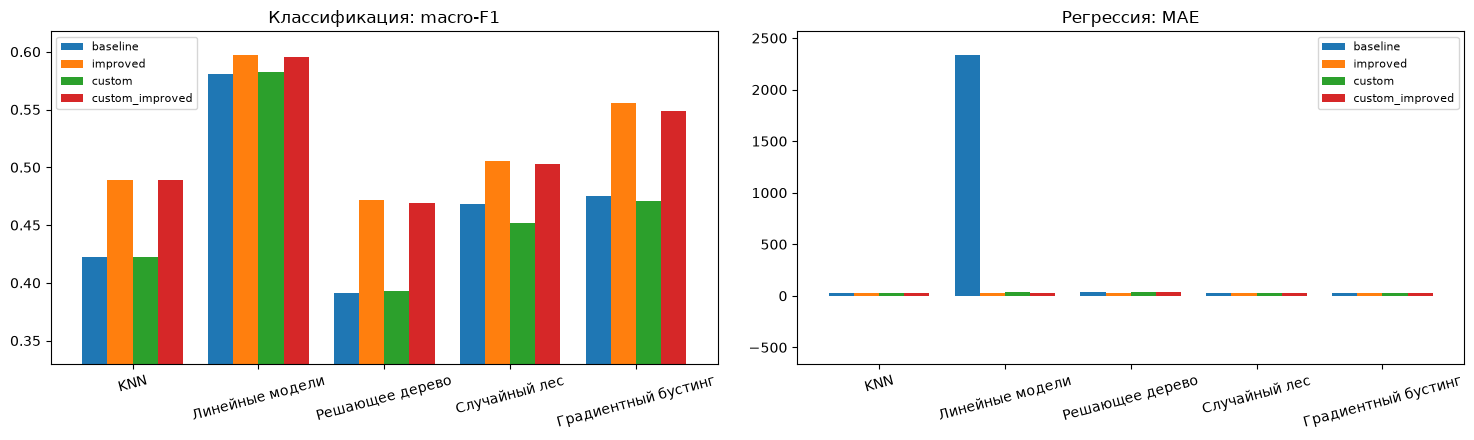

In [5]:
# Сгруппированные столбцы: основная метрика каждой задачи, алгоритм x этап
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, (task, metric, title) in zip(ax, [("classification", "f1_macro", "Классификация: macro-F1"),
                                          ("regression", "mae", "Регрессия: MAE")]):
    p = df[df["задача"] == task].pivot_table(index="алгоритм", columns="этап", values=metric, sort=False)[STAGES]
    p.plot.bar(ax=a, rot=15, width=0.8)
    a.set_title(title); a.set_xlabel("")
    lo, hi = p.min().min(), p.max().max()
    a.set_ylim(lo - (hi - lo) * 0.3, hi + (hi - lo) * 0.1)
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Лучшая модель каждого алгоритма

In [6]:
# Для каждого алгоритма - лучший этап по основной метрике; итоговый рейтинг
best_c = clf.loc[clf.groupby("алгоритм")["f1_macro"].idxmax(), ["алгоритм", "этап", "f1_macro", "accuracy"]].sort_values("f1_macro", ascending=False)
best_r = reg.loc[reg.groupby("алгоритм")["mae"].idxmin(), ["алгоритм", "этап", "mae", "rmse", "r2"]].sort_values("mae")
display(best_c.reset_index(drop=True)); display(best_r.reset_index(drop=True))

,алгоритм,этап,f1_macro,accuracy
0,Линейные модели,improved,0.5971,0.6004
1,Градиентный бустинг,improved,0.5559,0.5667
2,Случайный лес,improved,0.5056,0.5307
3,KNN,improved,0.4888,0.5154
4,Решающее дерево,improved,0.4715,0.4857


,алгоритм,этап,mae,rmse,r2
0,Линейные модели,improved,29.325,37.341,0.2336
1,Градиентный бустинг,improved,29.545,38.639,0.1794
2,KNN,improved,29.901,39.080,0.1605
3,Случайный лес,custom_improved,30.210,39.052,0.1617
4,Решающее дерево,improved,31.671,42.307,0.0162


## Эффект улучшений и качество собственных реализаций

In [7]:
# Прирост от улучшенного бейзлайна и разница собственная реализация - sklearn (на одинаковых признаках/параметрах)
def piv(t, m):
    return df[df["задача"] == t].pivot_table(index="алгоритм", columns="этап", values=m, sort=False)
pc, pr = piv("classification", "f1_macro"), piv("regression", "mae")
pd.DataFrame({
    "F1: improved-baseline": pc["improved"] - pc["baseline"],
    "F1: custom-baseline": pc["custom"] - pc["baseline"],
    "F1: custom_impr-improved": pc["custom_improved"] - pc["improved"],
    "MAE: improved-baseline": pr["improved"] - pr["baseline"],
    "MAE: custom-baseline": pr["custom"] - pr["baseline"],
    "MAE: custom_impr-improved": pr["custom_improved"] - pr["improved"],
}).round(4)

,F1: improved-baseline,F1: custom-baseline,F1: custom_impr-improved,MAE: improved-baseline,MAE: custom-baseline,MAE: custom_impr-improved
алгоритм,,,,,,
KNN,0.0662,0.0000,0.0000,-0.777,0.000,0.000
Линейные модели,0.0160,0.0012,-0.0013,-2305.406,-2299.420,0.030
Решающее дерево,0.0801,0.0016,-0.0025,-8.628,-0.008,0.798
Случайный лес,0.0372,-0.0170,-0.0030,-0.170,0.160,-0.040
Градиентный бустинг,0.0804,-0.0045,-0.0076,-1.791,-0.172,0.515


## Итоговые выводы

**Рейтинг алгоритмов (лучший этап каждого):**

| Место | Классификация (macro-F1) | Регрессия (MAE) |
|---|---|---|
| 1 | Линейные модели - 0.597 | Линейные модели (Ridge) - 29.33 |
| 2 | Градиентный бустинг - 0.556 | Градиентный бустинг - 29.55 |
| 3 | Случайный лес - 0.506 | KNN - 29.90 |
| 4 | KNN - 0.489 | Случайный лес - 30.21 |
| 5 | Решающее дерево - 0.472 | Решающее дерево - 31.67 |

1. **Лучшие модели в обеих задачах - линейные** (логистическая регрессия и Ridge на TF-IDF с биграммами). Для текстов с сотнями тысяч разреженных признаков линейная граница близка к оптимальной, обучение занимает секунды, а веса интерпретируемы.
2. **Градиентный бустинг - лучший из нелинейных** и в регрессии почти догоняет Ridge (29.55 против 29.33). Деревьям приходится работать на сжатом LSA-представлении (200 компонент), что теряет часть лексической информации.
3. **Одиночное дерево хуже всех**, а без ограничений переобучается до качества хуже константы. Ансамбли (лес, бустинг) исправляют это.
4. **Улучшенный бейзлайн помог всем алгоритмам.** Самые универсальные приёмы: плотное LSA-представление для KNN и деревьев, биграммы и регуляризация для линейных моделей, подбор сложности на CV. Самый большой эффект - у линейной регрессии (без регуляризации она непригодна) и у дерева.
5. **Собственные реализации** совпадают со sklearn: KNN - до последнего знака; линейные модели - с точностью до 0.002 F1; дерево, лес и бустинг - в пределах 0.01-0.02 F1, отличия объясняются гистограммным бинированием порогов и квадратичной функцией потерь.
6. **Задача регрессии существенно сложнее:** лучший R2 - 0.23, MAE снижается с ~33 (константа) до ~29 пунктов. Влияние новости на котировки определяется не только текстом, но и рыночным контекстом, которого в данных нет.
7. **Важность признаков согласована между алгоритмами:** для отзывов - лексика оценок ("10 из 10", "рекомендую", "дроп", "скучно") и сиквелов/сезонов; для новостей - нефть/баррель, рубль и курс, ставки и банки, санкции, длина статьи; деревья и бустинг также активно используют метаданные (источник, сфера "Энергетика").